# 08 - Testing the visual-semantic axis

*This notebook was added for the rebuttal.*

Our semantic axis comes from the classifier heads of different ImageNet models, and several of the 35 models we evaluate are closely related to them. This raises the question of whether the decline we see is circular.

Are we measuring the models with a ruler made out of the models themselves?

To test this, we:

1. Compare models that helped build the semantic axis with models that did not.
2. Check whether a model’s decline is strongest along its own classifier-head axis.
3. Build new axes from self-supervised models that are not part of our evaluation.
4. Use image retrieval as another way of measuring class distances from the same features.

In [ ]:
import os
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"

# Prediction CSVs from notebook 03 and the composite metadata from notebook 02
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
COMPOSITES_DIR = REPO_ROOT / "ImageNet-OOC1k" / "generated" / "composites"

# Semantic axes from notebook 01, and a folder for the new axes we build here
SEMANTIC_AXES_DIR = DATA_DIR / "semantic_axes"
NEW_AXES_DIR = SEMANTIC_AXES_DIR / "independent"
NEW_AXES_DIR.mkdir(parents=True, exist_ok=True)

# Backbone features of the ImageNet training images are saved here
FEATURES_DIR = OUTPUT_DIR / "features"

# The original ImageNet training set: a folder with one subfolder per class (change this to your copy)
IMAGENET_TRAIN = Path("/path/to/ImageNet/train")

# Model weight caches - None keeps the default caches
CACHE_DIR = None
if CACHE_DIR is not None:
    os.environ["HF_HOME"] = str(CACHE_DIR / "hf_cache")
    os.environ["TORCH_HOME"] = str(CACHE_DIR / "torch_cache")

# All evaluated models with composite predictions (all 35 if you ran notebook 03 with ALL_MODELS)
ALL_MODELS = sorted({path.name.split("_composite_ooc_")[0] for path in PREDICTIONS_DIR.glob("*_composite_ooc_*.csv")})

# Axis contributors: evaluated models whose classifier head is part of the consensus, and the name of that head
CONTRIBUTORS = {
    "ViT-B-16": "vit_base_patch16_224",
    "vit_small_patch16_224": "vit_small_patch16_224",
    "ViT-L-16": "vit_large_patch16_224",
    "vit_base_patch32_224": "vit_base_patch32_224",
    "vit_base_patch16_384": "vit_base_patch16_384",
    "ResNet-50": "resnet50",
    "resnet101": "resnet101",
    "EfficientNet-B3": "efficientnet_b3",
}
CONSENSUS_HEADS = list(CONTRIBUTORS.values()) + ["efficientnet_b5", "densenet121"]
STEEP_HEAD = "resnet101"    # left out of the "other axes" average in question 2

# Contributors and non-contributing siblings of the two families that have both
FAMILY_CONTRASTS = {
    "ResNet": (["ResNet-50", "resnet101"], ["resnet34", "ssl_resnet50"]),
    "EfficientNet": (["EfficientNet-B3"], ["efficientnet_b2", "efficientnet_b4", "efficientnetv2_rw_s", "efficientnetv2_rw_m"]),
}

# Self-supervised backbones with weight tag and input size (None = the backbone's default; DINOv2 would use 518 pixels)
BACKBONES = {
    "DINOv1": ("vit_base_patch16_224.dino", None),
    "DINOv2": ("vit_base_patch14_dinov2.lvd142m", 224),
    "MAE": ("vit_base_patch16_224.mae", None),
}
N_PER_CLASS = 100           # ImageNet training images per class
N_TRAIN = 90                # of these, used to train the probes; the rest measure their accuracy
N_RETRIEVAL = 50            # of these, used for retrieval
BATCH_SIZE = 256
NUM_WORKERS = 16

CLIP_MODEL = "CLIP-ViT-B-16"  # shown separately along the CLIP text axis in the last figure
MIN_HOP_COMPOSITES = 1000   # WordNet hop counts with fewer composites are left out of the last figure

BIN_WIDTH = 25              # ranks per bin, as in notebook 05
SEED = 42

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Feature extraction, analysis and plotting functions live outside the notebook to keep it readable.
from ooc1k.inference.frozen_features import extract_features, sample_imagenet_train
from ooc1k.analysis.semantic_distance import get_wordnet_hops, load_class_hash_index, load_composite_correctness
from ooc1k.analysis.visual_semantic_axes import (
    build_consensus,
    fit_linear_probe,
    get_accuracy_drops,
    get_axis_agreement,
    get_axis_curves,
    get_axis_ranks,
    get_cosine_dissimilarity,
    get_curve_summary,
    get_hop_curves,
    get_retrieval_axis,
    permutation_test,
)
from ooc1k.plotting.c_controls import get_display_name
from ooc1k.plotting.g_visual_semantic_axes import plot_other_axes, plot_probe_axes, plot_visual_axes

/pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/conda/envs/ooc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Setup

We use all 35 evaluated models and divide them into three groups, as in the rebuttal:

- **Axis contributors:** the eight evaluated models whose classifier heads helped build the consensus axis (`CONTRIBUTORS`). The other two heads in the consensus, EfficientNet-B5 and DenseNet-121, are not among the evaluated models.
- **Non-contributing siblings:** the six evaluated ResNet and EfficientNet models that did not contribute (`FAMILY_CONTRASTS`).
- **Independent families:** the remaining 21 models, from DeiT, BEiT, ConvNeXt, Inception and CLIP.

All four questions use the same predictions. For every composite, we only need to know whether each model got it right (top-1), and the classes of the background and the object. With these, we can place the composites on any axis: we rank the object class among the neighbours of the background class under that axis, just like notebook 02 did with the consensus, and group the ranks into bins of `BIN_WIDTH`. As in notebook 05, the **decline** of a model is its accuracy in the first bin minus its accuracy in the last bin, in percentage points.

In [3]:
correct = load_composite_correctness(PREDICTIONS_DIR, COMPOSITES_DIR / "metadata.csv", CLASS_INDEX, ALL_MODELS)
metadata = pd.read_csv(COMPOSITES_DIR / "metadata.csv", usecols=["background_class_hash", "object_class_hash"])
hash_to_idx = load_class_hash_index(CLASS_INDEX)
background_idx = metadata["background_class_hash"].map(hash_to_idx).values
object_idx = metadata["object_class_hash"].map(hash_to_idx).values


def get_curves(dissimilarity):
    """Accuracy of every model per rank bin, with the composites ranked under the given axis."""
    return get_axis_curves(get_axis_ranks(dissimilarity, background_idx, object_idx), correct, BIN_WIDTH)


def summarise(curves_by_axis):
    """First bin, lowest bin, last bin, decline and monotonicity of the mean curve over all models, per axis."""
    summary = pd.DataFrame({name: get_curve_summary(curves.mean(axis=1)) for name, curves in curves_by_axis.items()}).T
    return summary.astype({"lowest at bin": int})


consensus = np.load(SEMANTIC_AXES_DIR / "consensus.npy")
consensus_curves = get_curves(consensus)
consensus_drops = get_accuracy_drops(consensus_curves)
print(f"{len(correct):,} composites, {len(ALL_MODELS)} models")
print(f"Mean decline along the consensus: {consensus_drops.mean():.1f} percentage points")

953,862 composites, 35 models
Mean decline along the consensus: 14.5 percentage points


## 1. Does model overlap inflate the decline?

If the axis only measured how much a model agrees with itself, the axis contributors should decline the most. So we compare the mean decline of the three groups, test with a permutation test whether contributors decline more than all other models together, and compare contributors and siblings within the same family, where the architectures are most alike.

The contributors decline a bit more than the independent families, but less than their non-contributing siblings, and the difference to all other models is not significant. Within ResNet and EfficientNet, the siblings decline at least as much as the contributors. So helping to build the axis does not make a model decline more steeply along it.

In [4]:
groups = pd.Series("Independent families", index=ALL_MODELS)
groups[[model for _, siblings in FAMILY_CONTRASTS.values() for model in siblings]] = "Non-contributing siblings"
groups[list(CONTRIBUTORS)] = "Axis contributors"

difference, p_value = permutation_test(consensus_drops[groups == "Axis contributors"], consensus_drops[groups != "Axis contributors"], seed=SEED)
print(f"Contributors decline {difference:+.2f} pp more than all other models (permutation test: p = {p_value:.3f})")
for family, (contributors, siblings) in FAMILY_CONTRASTS.items():
    print(f"{family}: contributors {consensus_drops[contributors].mean():.1f} pp, siblings {consensus_drops[siblings].mean():.1f} pp")

# Number of models and mean decline per group, in percentage points
table = consensus_drops.groupby(groups).agg(["count", "mean"]).loc[["Axis contributors", "Non-contributing siblings", "Independent families"]]
table.loc["All models"] = [len(consensus_drops), consensus_drops.mean()]
table.set_axis(["n", "decline (pp)"], axis=1).astype({"n": int}).round(1)

Contributors decline +1.23 pp more than all other models (permutation test: p = 0.282)
ResNet: contributors 15.7 pp, siblings 17.0 pp
EfficientNet: contributors 17.4 pp, siblings 17.4 pp


,n,decline (pp)
Axis contributors,8,15.4
Non-contributing siblings,6,17.2
Independent families,21,13.3
All models,35,14.5


## 2. Do models decline more strongly along their own axes?

If circularity mattered, every contributor should decline most when the composites are ranked by its own classifier head. Notebook 01 saved all ten heads of the consensus, so we rank the composites by each head separately and compare each contributor's decline along its own head with its mean decline along the other contributing heads.

One head stands out: ranking by the ResNet-101 head makes almost every model decline very steeply, not only ResNet-101 itself. We therefore leave this head (`STEEP_HEAD`) out when we average over the other axes, otherwise it would cover up any advantage of a model's own head. For ResNet-101 itself, the other axes are simply the remaining nine.

Only three of the seven models (leaving out ResNet-101) decline more along their own axis, and on average by less than half a percentage point. ResNet-101 declines a lot more along its own axis, but so does every other model: its head is simply a steep axis for everyone, not a mirror of ResNet-101 itself.

In [5]:
head_drops = pd.DataFrame({head: get_accuracy_drops(get_curves(np.load(SEMANTIC_AXES_DIR / "individual_heads" / f"{head}.npy"))) for head in CONSENSUS_HEADS})

# Decline along the own axis versus the mean decline along the other axes.
own_axis = pd.DataFrame({
    model: {
        "own axis": head_drops.loc[model, head],
        "other axes": head_drops.loc[model, [other for other in CONSENSUS_HEADS if other not in (head, STEEP_HEAD)]].mean(),
    }
    for model, head in CONTRIBUTORS.items()
}).T
own_axis["difference"] = own_axis["own axis"] - own_axis["other axes"]

print(f"Along the ResNet-101 axis, the other {len(ALL_MODELS) - 1} models decline by {head_drops[STEEP_HEAD].drop(index=STEEP_HEAD).mean():.1f} pp on average")

# Declines in percentage points; the mean leaves out ResNet-101
rest = own_axis.drop(index=STEEP_HEAD).sort_values("difference", ascending=False)
table = pd.concat([rest, rest.mean().to_frame("Mean, excluding ResNet-101").T, own_axis.loc[[STEEP_HEAD]]])
table.rename(index=lambda model: get_display_name(model) if model in CONTRIBUTORS else model).round(1)

Along the ResNet-101 axis, the other 34 models decline by 20.5 pp on average


,own axis,other axes,difference
EfficientNet-B3,13.6,11.9,1.7
ResNet-50,11.5,10.5,1.0
ViT-B-16,9.8,8.8,0.9
ViT-B-32,14.0,14.0,-0.0
ViT-L-16,9.3,9.4,-0.1
ViT-S-16,13.6,14.2,-0.7
ViT-B-16-384,7.9,8.7,-0.9
"Mean, excluding ResNet-101",11.4,11.1,0.3
ResNet-101,24.3,10.9,13.5


## 3. Does the axis capture visual-semantic structure or ImageNet dataset bias?

The strongest test is to build an axis from models that have nothing to do with the ones we evaluate. We use three self-supervised Vision Transformers: **DINOv1** and **MAE** were trained on ImageNet images without any labels, and **DINOv2** on the much larger LVD-142M dataset (which also contains ImageNet images, but no labels). None of them contributed to the consensus, and none is among the 35 evaluated models.

These backbones have no ImageNet classifier head, so we train one. We take `N_PER_CLASS` ImageNet **training** images per class (so none of them appears in our composites, which come from the validation set), pass them through the frozen backbone, and train a **linear probe** on the features of the first `N_TRAIN` images per class. The remaining images tell us how well the probe classifies. The probe weights then take the place of the classifier head in Eq. 1: one row per class, compared with cosine dissimilarity. Finally, we combine the three probe axes into a **probe consensus** with Eq. 2, just like the original consensus.

From the same DINOv2 features, we also build the two retrieval axes of question 4 here (see there for how they work).

Extracting the features takes a few minutes per backbone on one GPU. They are saved in `FEATURES_DIR`, and loaded from there when you run the cell again.

In [6]:
images = sample_imagenet_train(IMAGENET_TRAIN, CLASS_INDEX, N_PER_CLASS, seed=SEED)

features = {}
for name, (timm_name, img_size) in BACKBONES.items():
    features[name] = extract_features(timm_name, images, IMAGENET_TRAIN, FEATURES_DIR / f"{name}.npz", img_size=img_size, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

print(f"Features of {len(images):,} ImageNet training images saved in {FEATURES_DIR}")

Features of 100,000 ImageNet training images saved in /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/outputs/features


In [7]:
# Probe axes: a linear probe per backbone, its weights compared with Eq. 1, and their consensus with Eq. 2
probe_axes, probe_accuracy = {}, {}
for name, result in features.items():
    weights, probe_accuracy[f"{name} probe"] = fit_linear_probe(result["features"], result["class_idx"], result["within_class"] < N_TRAIN, seed=SEED)
    probe_axes[f"{name} probe"] = get_cosine_dissimilarity(weights)
probe_axes["Probe consensus"] = build_consensus(list(probe_axes.values()))

for name, D in probe_axes.items():
    np.save(NEW_AXES_DIR / f"{name.lower().replace(' ', '_')}.npy", D)
print(f"Saved {len(probe_axes)} probe axes to {NEW_AXES_DIR}")

Saved 4 probe axes to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/data/semantic_axes/independent


In [8]:
# Retrieval axes from the DINOv2 features: best match, and mean of the five best matches
dinov2 = features["DINOv2"]
first = dinov2["within_class"] < N_RETRIEVAL
retrieval_axes = {
    "Retrieval, best match": get_retrieval_axis(dinov2["features"][first], dinov2["class_idx"][first], top_k=1),
    "Retrieval, top 5": get_retrieval_axis(dinov2["features"][first], dinov2["class_idx"][first], top_k=5),
}

for name, D in retrieval_axes.items():
    np.save(NEW_AXES_DIR / f"{name.lower().replace(',', '').replace(' ', '_')}.npy", D)
print(f"Saved {len(retrieval_axes)} retrieval axes to {NEW_AXES_DIR}")

Saved 2 retrieval axes to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/data/semantic_axes/independent


Does accuracy still decline along the probe axes? The table shows how well each probe classifies the held-out images, how closely each axis agrees with the original consensus (Spearman correlation over all pairs of classes), and the mean accuracy over all models in the first bin, in the lowest bin (and which of the 40 bins that is), and in the last bin, the decline, and the **monotonicity**: the Spearman correlation between bin number and accuracy, where −1 means the accuracy falls in every single step.

All three probe axes and the probe consensus show the decline: accuracy is highest in the first bin, lowest in the last one, and falls almost steadily in between, even though the probe axes agree only moderately with the original consensus. The declines are somewhat smaller, but the models that decline most along the original consensus also decline most along the probe consensus. The MAE probe classifies much worse than the DINO probes, as MAE features are known to be hard to read out with a linear classifier, so DINOv1 and DINOv2 are the cleaner tests.

So the decline does not depend on the classifier heads of the evaluated models, or on supervised ImageNet training of the features. It does still depend on the ImageNet classes, though, since the probes are trained on ImageNet labels.

In [9]:
probe_curves = {name: get_curves(D) for name, D in probe_axes.items()}
probe_drops = get_accuracy_drops(probe_curves["Probe consensus"])
print(f"Per model, the declines along the probe consensus and the original consensus correlate with r = {np.corrcoef(consensus_drops, probe_drops)[0, 1]:.3f}")

table = summarise({"Original consensus": consensus_curves, **probe_curves})
table.insert(0, "probe accuracy (%)", 100 * pd.Series(probe_accuracy))
table.insert(1, "agreement with consensus", pd.Series({name: get_axis_agreement(D, consensus) for name, D in {"Original consensus": consensus, **probe_axes}.items()}))
table.round(2)

Per model, the declines along the probe consensus and the original consensus correlate with r = 0.969


,probe accuracy (%),agreement with consensus,first bin (%),lowest bin (%),lowest at bin,last bin (%),decline (pp),monotonicity
Original consensus,NaN,1.00,66.90,52.44,40,52.44,14.46,-0.98
DINOv1 probe,74.74,0.25,63.77,55.67,40,55.67,8.11,-0.95
DINOv2 probe,81.22,0.24,64.76,54.57,40,54.57,10.19,-0.98
MAE probe,40.65,0.56,65.28,52.81,40,52.81,12.46,-0.91
Probe consensus,NaN,0.50,65.19,53.19,40,53.19,12.00,-0.99


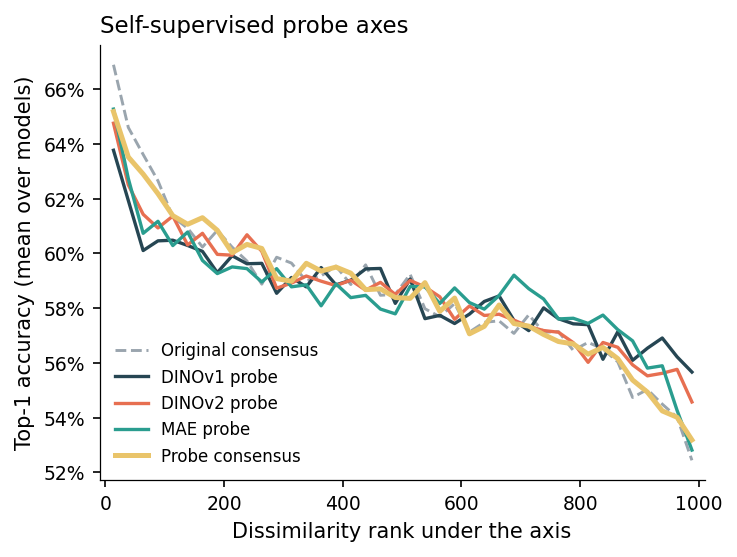

In [10]:
fig = plot_probe_axes({name: curves.mean(axis=1) for name, curves in probe_curves.items()}, reference=consensus_curves.mean(axis=1))
fig.savefig(FIG_DIR / "axis_probes.pdf")
plt.show()

## 4. Does the decline replicate using retrieval-based visual distances?

Here, nothing is trained. We simply ask how similar the images of two classes look: for every image of one class, we find its best match among the images of the other class and average the cosine similarity over all images. Since a single best match is a bit noisy, we also try the mean of the five best matches. The axes were built above from the same DINOv2 features (the first `N_RETRIEVAL` images per class), so only the readout changes compared to the DINOv2 probe.

Neither retrieval axis reproduces the decline. Accuracy first drops, reaches its lowest point in the first half of the axis, and then rises again, ending even above where it started. The DINOv2 probe, built from the very same features, declines all the way. Retrieval measures whether two classes contain similar-looking images, while the probe captures what separates the classes when a model has to decide between them. So the decline follows the discriminative structure of the classes, not just any notion of visual similarity.

In [11]:
retrieval_curves = {name: get_curves(D) for name, D in retrieval_axes.items()}
summarise({"DINOv2 probe": probe_curves["DINOv2 probe"], **retrieval_curves}).round(2)

,first bin (%),lowest bin (%),lowest at bin,last bin (%),decline (pp),monotonicity
DINOv2 probe,64.76,54.57,40,54.57,10.19,-0.98
"Retrieval, best match",64.40,55.20,16,66.63,-2.24,0.38
"Retrieval, top 5",64.54,56.13,12,66.62,-2.09,0.20


## Putting it together

Here we are putting all the information we gathered in this notebook and Notebook 5 (this one already compared the consensus with a few other ways of measuring how related two classes are) into single plots.

The first figure shows the axes built from visual features. (a) The single classifier heads that make up the consensus and (b) the probes trained on frozen self-supervised features both decline, although the single heads less steadily than the consensus. (c) Retrieval from the same DINOv2 features as the DINOv2 probe does not: only the readout changes, and the curve becomes U-shaped.

The second figure shows similarities that do not come from visual features. Here, every model is drawn as a thin line, with the mean over models in bold and CLIP in orange. Along (a) CLIP text embeddings of the class names, accuracy even rises for most models; only CLIP itself (orange) declines, which makes sense, since CLIP was trained to match images with exactly these text embeddings. Along (b) the number of hops in WordNet, accuracy is U-shaped, for the mean as well as for the single models.

So the decline is not something any ordering of the classes would produce. It follows how visual classifiers separate the ImageNet classes.

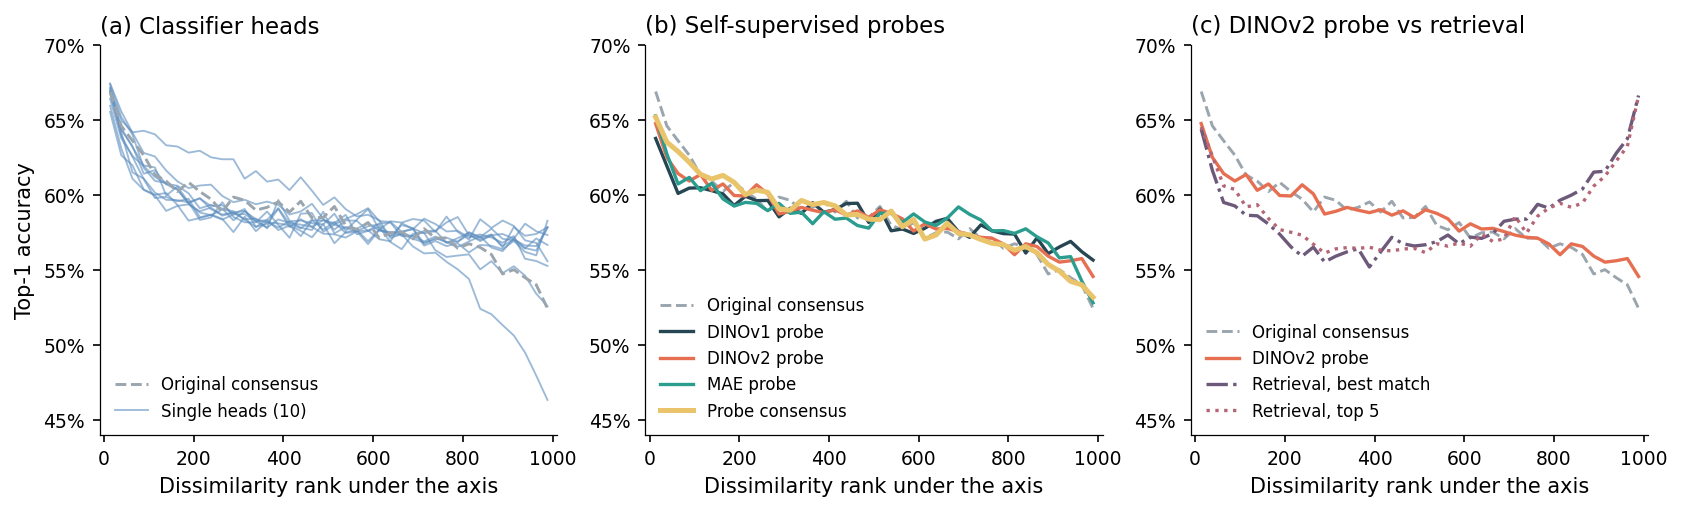

In [12]:
head_curves = {head: get_curves(np.load(SEMANTIC_AXES_DIR / "individual_heads" / f"{head}.npy")).mean(axis=1) for head in CONSENSUS_HEADS}

fig = plot_visual_axes(
    head_curves=head_curves,
    probe_curves={name: curves.mean(axis=1) for name, curves in probe_curves.items()},
    retrieval_curves={name: curves.mean(axis=1) for name, curves in {"DINOv2 probe": probe_curves["DINOv2 probe"], **retrieval_curves}.items()},
    reference=consensus_curves.mean(axis=1),
)
fig.savefig(FIG_DIR / "axis_validation_visual.pdf")
plt.show()

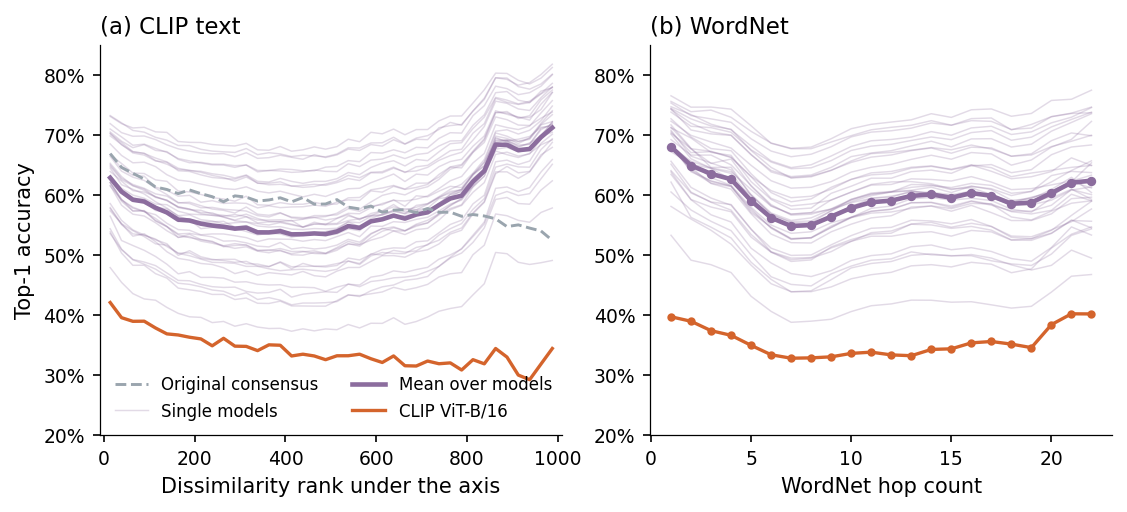

,first bin (%),lowest bin (%),lowest at bin,last bin (%),decline (pp),monotonicity
"CLIP text, mean over models",62.88,53.45,17,71.22,-8.35,0.44
"CLIP text, CLIP alone",42.09,29.23,38,34.43,7.66,-0.85


In [13]:
clip_text_curves = get_curves(np.load(SEMANTIC_AXES_DIR / "clip_text.npy"))
hops = get_wordnet_hops(np.load(SEMANTIC_AXES_DIR / "wordnet.npy"))[background_idx, object_idx]

fig = plot_other_axes(
    clip_text_curves=clip_text_curves,
    wordnet_curves=get_hop_curves(hops, correct, MIN_HOP_COMPOSITES),
    reference=consensus_curves.mean(axis=1),
    clip_model=CLIP_MODEL,
)
fig.savefig(FIG_DIR / "axis_validation_other.pdf")
plt.show()

summarise({"CLIP text, mean over models": clip_text_curves, "CLIP text, CLIP alone": clip_text_curves[[CLIP_MODEL]]}).round(2)